# 02.5 · Many features: multiple linear regression

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/05-multiple-regression/lesson.ipynb)

Read the [README](README.md) first. Here: the three-feature model on the 20 customers, reading its coefficients, one-hot country, then six features on the real data and a coefficient that looks wrong but is not.

## 1. One feature, then three

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest
import pandas as pd

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
cust20.head()

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1


In [2]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<28} MAE £{mae:8.1f}   RMSE £{rmse:8.1f}   R² {r2:6.3f}")

from sklearn.linear_model import LinearRegression
y = cust20["spend_next_month"]

one = LinearRegression().fit(cust20[["visits_last_month"]], y)
print(f"visits only:  spend = {one.intercept_:.2f} + {one.coef_[0]:.2f} × visits")

feats = ["visits_last_month", "items_last_month", "days_since_last"]
three = LinearRegression().fit(cust20[feats], y)
print(f"three feats:  spend = {three.intercept_:.1f} + " +
      " + ".join(f"{b:.2f} × {f}" for b, f in zip(three.coef_, feats)))

visits only:  spend = 19.61 + 17.17 × visits
three feats:  spend = 38.1 + 12.58 × visits_last_month + 7.65 × items_last_month + -0.70 × days_since_last


In [3]:
report("visits only", y, one.predict(cust20[["visits_last_month"]]))
report("visits + items + days", y, three.predict(cust20[feats]))

visits only                  MAE £    10.7   RMSE £    13.5   R²  0.962
visits + items + days        MAE £     7.8   RMSE £     9.0   R²  0.983


## 2. Predict by plugging in

The three customers from the README table. `predict` does the arithmetic you did by hand.

In [4]:
rows = cust20.set_index("customer_id").loc[["C001", "C006", "C009"], feats]
pred = three.predict(rows)
out = rows.assign(predicted=pred.round(1), actual=y[cust20["customer_id"].isin(["C001", "C006", "C009"])].to_numpy(),
                  visits_only=one.predict(rows[["visits_last_month"]]).round(1))
out

,visits_last_month,items_last_month,days_since_last,predicted,actual,visits_only
customer_id,,,,,,
C001,2,2,55,40.0,27.61,54.0
C006,13,7,20,241.2,250.03,242.9
C009,3,3,5,95.3,94.82,71.1


C001's 55 silent days pull the prediction from £54 (visits only) to £40, closer to the £27.6 they really spent. That is what the third feature buys.

## 3. The visits coefficient changed. Why?

17.17 per visit alone; 12.58 per visit next to items and days. Visits and items are correlated, so when the model can see both it splits the credit between them.

In [5]:
print("correlation between the features:")
print(cust20[feats].corr().round(2))

correlation between the features:
                   visits_last_month  items_last_month  days_since_last
visits_last_month               1.00              0.94            -0.22
items_last_month                0.94              1.00            -0.09
days_since_last                -0.22             -0.09             1.00


A coefficient is always "per unit, **holding the other features in this model fixed**". Change the list of features and every coefficient can move.

## 4. A categorical feature: country

Countries have no "one unit". `get_dummies` turns the column into 0/1 indicator columns; `drop_first=True` leaves out one category (DE here) to serve as the reference. Each coefficient is then "difference from DE, everything else equal".

In [6]:
X_cat = pd.get_dummies(cust20[feats + ["country"]], columns=["country"], drop_first=True, dtype=int)
display(X_cat.head())
with_country = LinearRegression().fit(X_cat, y)
print(pd.Series(with_country.coef_, index=X_cat.columns).round(2))
print(f"intercept {with_country.intercept_:.1f}")
report("+ country", y, with_country.predict(X_cat))

,visits_last_month,items_last_month,days_since_last,country_FR,country_UK
0,2,2,55,0,1
1,11,8,44,1,0
2,10,6,22,0,0
3,7,6,58,0,1
4,7,5,25,1,0


visits_last_month    12.41
items_last_month      7.63
days_since_last      -0.81
country_FR           15.08
country_UK            7.32
dtype: float64
intercept 37.0
+ country                    MAE £     6.4   RMSE £     7.7   R²  0.988


FR +£15, UK +£7 relative to DE, with the other features fixed. R² moved from 0.983 to 0.988 on twenty rows: two extra columns, half a point. Not evidence of a real country effect; evidence that extra columns always raise training R² a little (section 8 of the README). Module 04 shows how to tell the two apart.

## 5. Predicted vs actual

The plot to make for any regression: if the model were perfect, every point would sit on the diagonal.

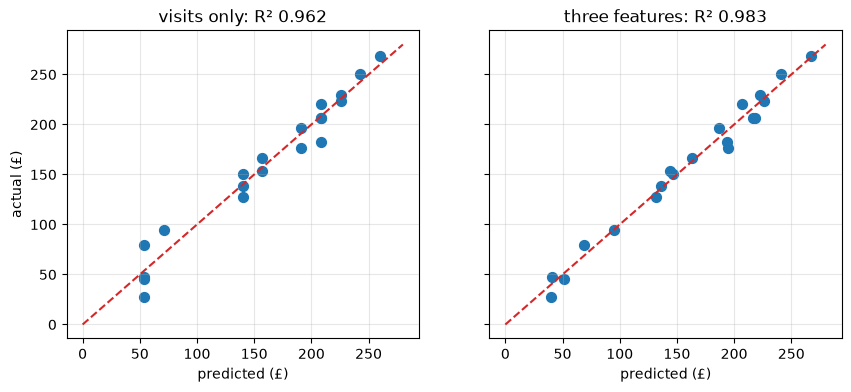

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, model, X) in zip(axes, [("visits only", one, cust20[["visits_last_month"]]),
                                        ("three features", three, cust20[feats])]):
    p = model.predict(X)
    ax.scatter(p, y, s=50)
    ax.plot([0, 280], [0, 280], color="tab:red", linestyle="--")
    ax.set(title=f"{name}: R² {r2_score(y, p):.3f}", xlabel="predicted (£)"); ax.grid(alpha=.3)
axes[0].set_ylabel("actual (£)")
plt.show()

## 6. The real data: six features

The customer table from 01.9: features from before 1 Sep 2011, target = spend in Sep–Nov 2011.

In [8]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()


def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")


cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"),
    country=("Country", "first"))
cust["avg_order"] = cust["spend"] / cust["orders"]
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
cust["spend_next_quarter"] = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust = cust.drop(columns=["first_order", "last_order"])
print(f"{len(cust):,} customers; features from before {cutoff.date()}, target = spend Sep–Nov 2011")
cust.head()

(541910, 8)
541,910 rows → 392,693 after cleaning


3,317 customers; features from before 2011-09-01, target = spend Sep–Nov 2011


,orders,spend,products,items,country,avg_order,tenure_days,days_since_last,spend_next_quarter
Customer ID,,,,,,,,,
12346,1,77183.60,1,74215,United Kingdom,77183.600000,225,225,0.00
12347,5,2790.86,82,1590,Iceland,558.172000,267,29,1294.32
12348,3,1487.24,22,2124,Finland,495.746667,258,148,310.00
12350,1,334.40,17,197,Norway,334.400000,210,210,0.00
12352,5,1561.81,26,254,Norway,312.362000,196,162,944.23


In [9]:
feats_real = ["orders", "spend", "products", "avg_order", "tenure_days", "days_since_last"]
y_real = cust["spend_next_quarter"]

single = LinearRegression().fit(cust[["spend"]], y_real)
multi = LinearRegression().fit(cust[feats_real], y_real)
report("past spend only", y_real, single.predict(cust[["spend"]]))
report("six features", y_real, multi.predict(cust[feats_real]))

past spend only              MAE £   547.1   RMSE £  2260.4   R²  0.669
six features                 MAE £   556.5   RMSE £  2076.4   R²  0.720


In [10]:
coefs = pd.Series(multi.coef_, index=feats_real).round(3)
print(coefs)
print(f"intercept {multi.intercept_:.1f}")

orders            -9.740
spend              0.616
products          -0.581
avg_order         -0.681
tenure_days       -2.209
days_since_last    1.238
dtype: float64
intercept 413.5


Six features bought five points of R² and a better RMSE, while MAE got slightly worse: the extra columns help on the big customers that dominate squared error and do nothing for the typical one. Now read the coefficients and find the one that looks wrong: `days_since_last` is **positive**. More days of silence, *more* predicted spend?

Check the raw relationship first.

In [11]:
print("correlation of days_since_last with the target:", cust["days_since_last"].corr(y_real).round(3))
print("median next-quarter spend by recency band:")
bands = pd.cut(cust["days_since_last"], [0, 30, 90, 180, 400])
print(cust.groupby(bands, observed=True)["spend_next_quarter"].median().round(0))

correlation of days_since_last with the target: -0.131
median next-quarter spend by recency band:
days_since_last
(0, 30]       530.0
(30, 90]      236.0
(90, 180]       0.0
(180, 400]      0.0
Name: spend_next_quarter, dtype: float64


Alone, recency is *negatively* related to future spend, as common sense says. The coefficient is positive because it is "holding `spend` and `orders` fixed": among customers with the *same* past spend and order count, the ones with a long gap are the big infrequent wholesale buyers, who do spend more when they return. The model is right about its own question; the question is just not the one you had in mind. **Coefficients describe the model, not the world.** Module 05 (SHAP) gives tools that explain predictions more honestly.

## Quiz answers

1. The change in the prediction for a one-unit increase in $x_1$, holding $x_2$ (and every other feature in the model) fixed.
2. No. Part of the effect it was carrying is now attributed to items, which is correlated with visits. Its "importance" did not change; its *share of credit* did.
3. If all categories had a column, they would always sum to 1, duplicating the intercept; the model could not separate them. The left-out category becomes the reference.
4. Correlated features splitting credit (multicollinearity); the coefficient being conditional on other features (as with `days_since_last`); too few rows; an outlier.
5. No. Least squares can always set the new coefficient to 0 and keep the old fit, so training R² can only stay equal or rise.

**Next:** [02.6 Curves and overfitting](../06-polynomial-and-overfitting/)